# `BeamColumnJoint` — full design walkthrough

This notebook exercises the **entire public API** of the `BeamColumnJoint` element of
`design/` (ACI 318‑25), following one **canonical 12‑step flow**. Every element
— `Beam`, `Column`, `Wall`, `BeamColumnJoint` — shares this same skeleton, so the
*architecture* is identical and only the **physics** changes.

> **Rational structure.** The element is an immutable object. You *create* it,
> *run* it to cache capacities, *review* a given reinforcement against demands,
> let it *design* a proposal, and *adopt* that proposal by producing a **new**
> element. Reporting and plotting sit on top. The shared base class
> `design.common.element_base.ElementBase` provides the parts that are identical
> across elements (`apply`, `set_units`); the runtime `Element` protocol
> (`design.common.contracts`) is the canonical `isinstance` test.

### The 12‑step contract

| Step | Call | Purpose |
|------|------|---------|
| 1 | `Concrete(...)`, `Steel(...)` | materials (MPa) |
| 2 | `BeamColumnJoint.rectangular(...)` | **create** — every input argument shown |
| 3 | `el.run()` | lazy‑compute + cache capacity (returns `self`) |
| 4 | `el.capacity()` | capacity of the **as‑built** reinforcement |
| 5 | `el.demands(...)` | build the load set (display units → internal) |
| 6 | `el.check(demands)` | **review** the current rebar → PASS/FAIL |
| 7 | `el.design(demands)` | automatic **proposal** (multiple modes) |
| 8 | `results.envelope.<field>` | read the result **explicitly** (no magic) |
| 9 | `el.evolve(p)` / `el.apply(p)` | adopt → **new immutable** element |
| 10 | `report()` / `summary()` / `set_units()` / `print_final()` | reporting |
| 11 | `el.plot.*` | plotting |
| 12 | `el.run_optimize(demands)` | sweep detailing alternatives |

**Physics of this element.** A beam‑column joint is a **shear** check in each principal direction (ACI §15 / §18.8). It is assembled from real `Column` and `Beam` members and derives its demand from the members' interaction diagrams.

**By‑design exceptions.** Two steps differ **by design**: there is **no `rectangular()` factory** (the joint has no geometry of its own), **no `demand` mode** in `design()` (it is capacity‑designed to protect the beam/column mechanism), and **no `run_optimize`** (the confinement steel lives in the column).

> **Internal units (non‑negotiable):** stress = MPa, length = mm, force = kN,
> moment = kN·m, area = mm². The `units=` argument only controls *presentation*.


## Step 1 — Materials

In [1]:
# Notebook setup: inline figures, repo on sys.path, silence the metre→mm warning
%matplotlib inline
import sys, pathlib, warnings
warnings.simplefilter("ignore", DeprecationWarning)

# Make `design` importable whether or not the repo is pip-installed:
_root = pathlib.Path.cwd().resolve()
while _root != _root.parent and not (_root / "design" / "__init__.py").is_file():
    _root = _root.parent
if (_root / "design").is_dir() and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from design.common.materials import Concrete, Steel
from design.beams.beam import Beam
from design.columns.column import Column
from design.joints.joint import BeamColumnJoint, FramingBeam, JointDemands

concrete = Concrete(fc=35.0)
steel = Steel(fy=420.0)
concrete, steel

(Concrete(fc=35.0, unit_weight=24.0, lightweight=False, sand_lightweight=False),
 Steel(fy=420.0, Es=200000.0, fu=None, grade=60, density=7850.0))

## Step 2 — Assemble from real members

There is no factory: a joint is the **intersection** of a column (above/below) and up to four framing beams. We first build the members, then wrap the beams in `FramingBeam` (which carries the plan angle and eccentricity).

In [2]:
def make_column(label):
    return Column.rectangular(
        b=600, h=600, clear_cover=40, concrete=concrete, steel=steel,
        n_x=4, n_y=4, db_long=25, db_stirrup=12,
        n_legs_x=4, n_legs_y=4, s_stirrup=100, lu=3000.0, label=label)

def make_beam(label):
    return Beam.rectangular(
        bw=350, h=600, cover=40, concrete=concrete, steel=steel,
        n_top=4, db_top=25, n_bot=4, db_bot=25,
        db_stirrup=12, n_legs=2, s_stirrup=100, ln=6000.0, label=label)

bx, by = make_beam("Bx"), make_beam("By")
joint = BeamColumnJoint(
    col_above=make_column("C-top"), col_below=make_column("C-bot"),
    beam_left=FramingBeam(bx), beam_right=FramingBeam(bx),
    beam_up=FramingBeam(by), beam_down=FramingBeam(by),
    moment_condition="P0",   # beam moment at P=0 ('balanced' = peak)
    probable=True,           # 1.25·fy, phi=1.0 probable moments
    label="J-interior",
)
print("joint type =", joint.joint_type())
joint

joint type = interior


BeamColumnJoint(label='J-interior', type='interior')

## Step 3 — `run()`

In [3]:
joint.run()

BeamColumnJoint(label='J-interior', type='interior')

## Step 4 — `capacity()`

The effective joint area `Aj`, the `gamma` coefficient (Table 18.8.4.3) and `phi*Vn` for each principal direction.

In [4]:
cap = joint.capacity()
for axis, cd in (("X", cap.x), ("Y", cap.y)):
    print(f"[{axis}] Aj = {cd.Aj:.0f} mm²   gamma = {cd.gamma:.0f}   phi*Vn = {cd.phi_Vn:.0f} kN")

[X] Aj = 360000 mm²   gamma = 15   phi*Vn = 2254 kN
[Y] Aj = 360000 mm²   gamma = 15   phi*Vn = 2254 kN


## Step 5 — Demands (optional override)

By default the joint shear is **derived from the members**. `JointDemands` lets you override the per‑direction shear manually; leave a field `None` to keep the derived value.

In [5]:
demands = JointDemands(Vu_x=2500.0)   # Vu_y stays derived
print(f"override Vu_x = {demands.Vu_x} kN   (Vu_y derived)")

override Vu_x = 2500.0 kN   (Vu_y derived)


## Step 6 — `check(demands)`

In [6]:
chk = joint.check(demands)
print(f"ratio = {chk.ratio:.2f}   passed = {chk.passed}")
chk.summary()

ratio = 1.11   passed = False
=== Joint check — interior ===
  [X]  Vu =  2500.0 kN    phi*Vn =  2253.8 kN    ratio = 1.109    [FAIL]  (bars in core)
  [Y]  Vu =  1826.2 kN    phi*Vn =  2253.8 kN    ratio = 0.810    [PASS]  (bars in core)
  ---
  passed         : False


## Step 7 — `design()` — **no `demand` mode**

The joint is capacity‑designed: `design()` returns **minimum / capacity / envelope** only. There is deliberately no demand mode — the joint protects the beam/column mechanism rather than being sized to a specific demand.

In [7]:
results = joint.design()
joint.print_design(results)


  JOINT DESIGN — J-interior    (interior)

---------------------------- [ MINIMUM  ] ----------------------------
  s_max confined : 150 mm   (§18.8.3 / §18.7.5.3)
  Ash reduction  : False        (§18.8.3.2)
  ldh required   : 200 mm   (§18.8.5.1)
  min depth X    : 500 mm    provided = 600 mm
  min depth Y    : 500 mm    provided = 600 mm
  depth ok       : True
  note: Transverse reinforcement per §18.7.5.4 (use the column's confinement design).

---------------------------- [ CAPACITY ] ----------------------------
  s_max confined : 150 mm   (§18.8.3 / §18.7.5.3)
  Ash reduction  : False        (§18.8.3.2)
  ldh required   : 200 mm   (§18.8.5.1)
  min depth X    : 500 mm    provided = 600 mm
  min depth Y    : 500 mm    provided = 600 mm
  depth ok       : True
  note: Transverse reinforcement per §18.7.5.4 (use the column's confinement design).

---------------------------- [ ENVELOPE ] ----------------------------
  s_max confined : 150 mm   (§18.8.3 / §18.7.5.3)
  Ash reduction

## Step 8 — Read the result explicitly

In [8]:
env = results.envelope
print(f"mode          = {env.mode}")
print(f"hoop s_max    = {env.s_max_confined:.0f} mm   Ash relief = {env.ash_reduction}")
print(f"ldh required  = {env.ldh_required:.0f} mm")
print(f"min depth X/Y = {env.min_depth_x:.0f} / {env.min_depth_y:.0f} mm   ok = {env.depth_ok}")

mode          = envelope
hoop s_max    = 150 mm   Ash relief = False
ldh required  = 200 mm
min depth X/Y = 500 / 500 mm   ok = True


## Step 9 — `evolve()` / `apply()`

The joint geometry is member‑driven, so `evolve` returns an identical clone with a fresh cache — still honouring the immutability contract.

In [9]:
joint2 = joint.evolve(env)
assert joint2 is not joint
_ = joint.apply(env)
print("evolved joint type =", joint2.joint_type())

evolved joint type = interior


## Step 10 — Reporting

In [10]:
print("report keys =", sorted(joint2.report()))
joint2.set_units(6)   # code 6 = kN, m, °C
joint2.summary()
joint2.print_final(env, demands=demands)

report keys = ['Aj_x', 'Aj_y', 'Vu_x', 'Vu_y', 'gamma_x', 'gamma_y', 'joint_type', 'label', 'moment_condition', 'notes', 'passed', 'phi_Vn_x', 'phi_Vn_y', 'probable', 'ratio']


Joint J-interior — interior
  [X] Aj=360000 mm²  γ=15  φVn=2254 kN  Vu=1826 kN  ratio=0.81
  [Y] Aj=360000 mm²  γ=15  φVn=2254 kN  Vu=1826 kN  ratio=0.81
  passed = True

  JOINT — FINAL DESIGN   |   J-interior   |   interior
  Capacities (gross shear):
    [X]  Aj =  360000 mm²    gamma = 15    phi*Vn =   2254 kN
    [Y]  Aj =  360000 mm²    gamma = 15    phi*Vn =   2254 kN
------------------------------------------------------------------------
  Detailing (proposal):
    s_max confined : 150 mm   (§18.8.3 / §18.7.5.3)
    Ash reduction  : False   (§18.8.3.2)
    ldh required   : 200 mm   (§18.8.5.1)
    min depth X    : 500 mm    provided = 600    [PASS]
    min depth Y    : 500 mm    provided = 600
------------------------------------------------------------------------
  Code check vs demands:
    [X]  Vu =  2500.0 kN    phi*Vn =  2253.8 kN    ratio = 1.109    [FAIL]
    [Y]  Vu =  1826.2 kN    phi*Vn =  2253.8 kN    ratio = 0.810    [PASS]
  --------------------------------------

## Step 11 — Plotting

The joint plotter (new in this refactor): a plan view of the core (column footprint + framing beams) and the per‑direction shear demand‑vs‑capacity.

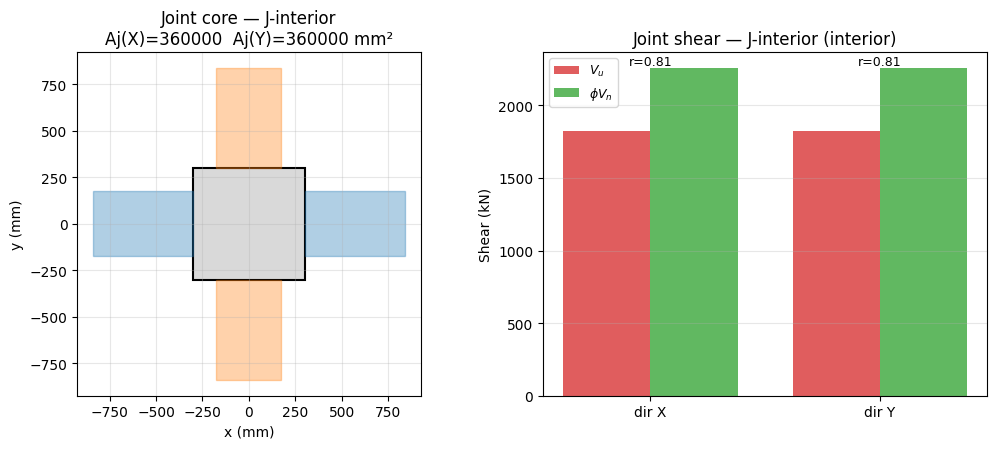

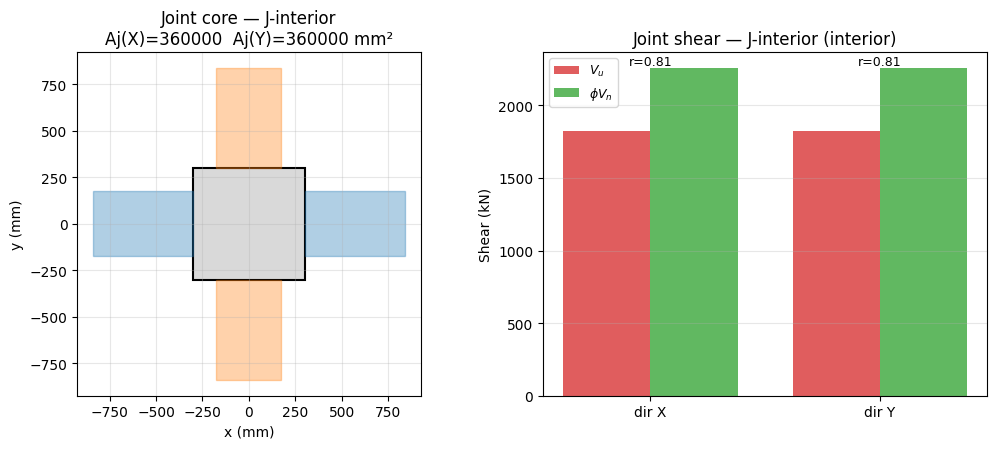

In [11]:
fig = joint.plot.dashboard()
fig

## Step 12 — `run_optimize` — N/A

A joint owns no reinforcement cage (the confinement steel is the column's), so there is nothing joint‑local to optimise.

In [12]:
print("Joints are checked, not steel-optimised — nothing to sweep.")

Joints are checked, not steel-optimised — nothing to sweep.


---
### Architecture recap

The joint proves the contract is robust: even an element with no geometry of its own, no factory and no demand mode still exposes the **same** `run / capacity / check / design / evolve / apply / report / summary / set_units / plot` surface as the other three.